(21600, 38)


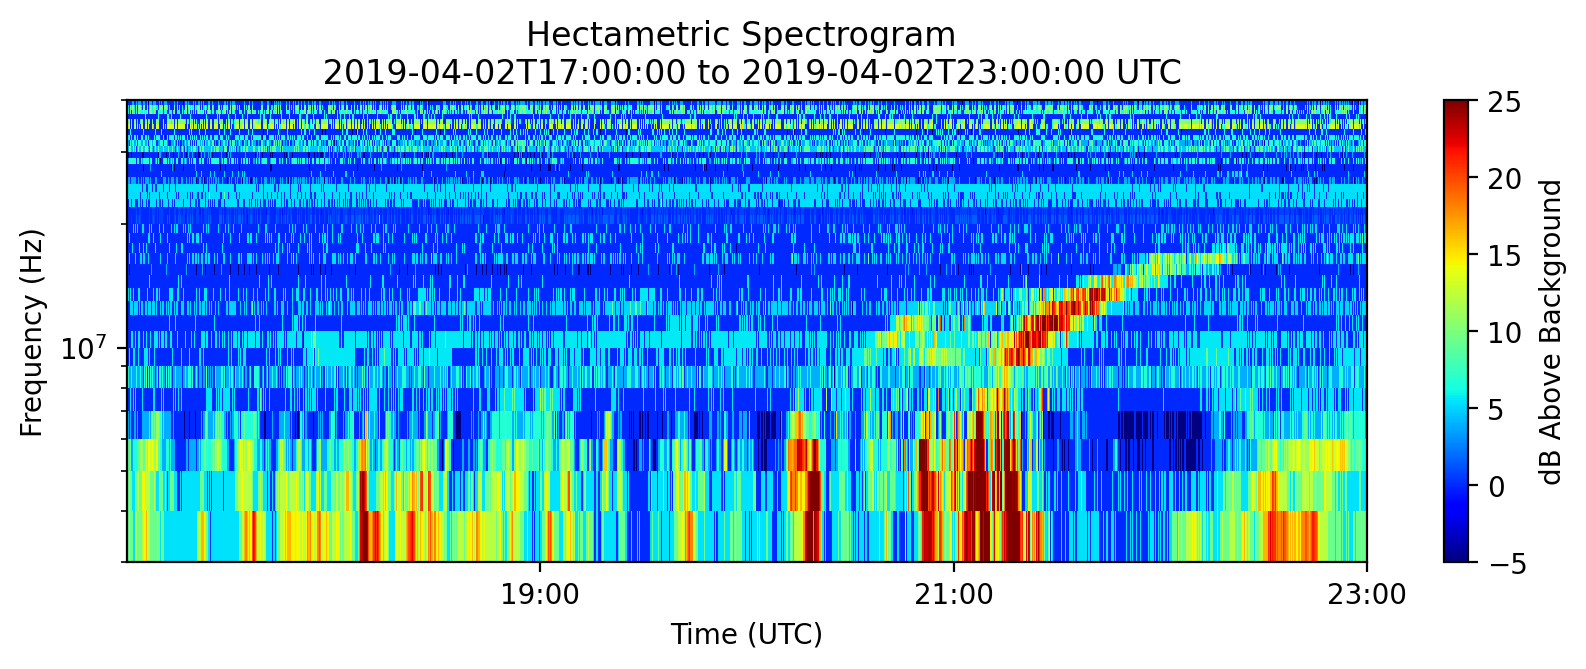

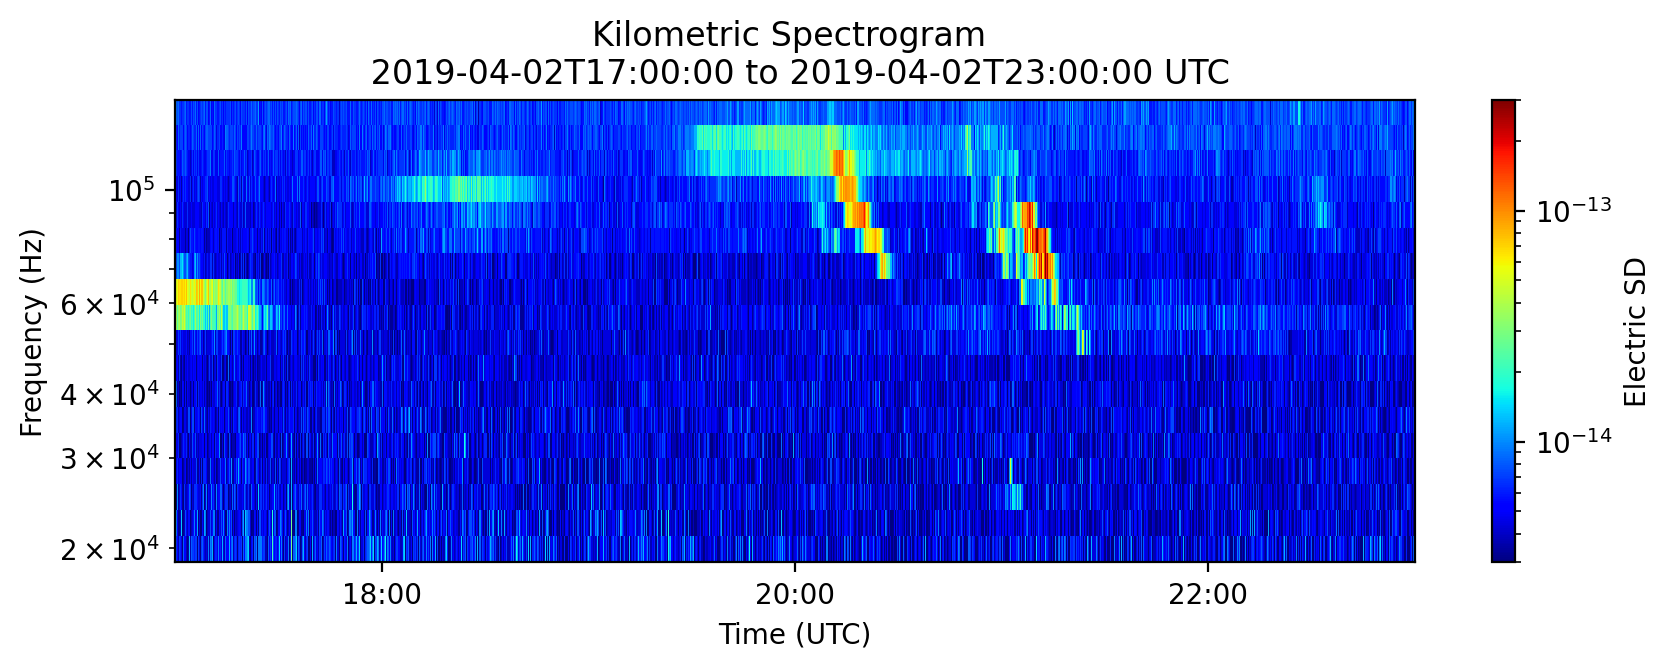

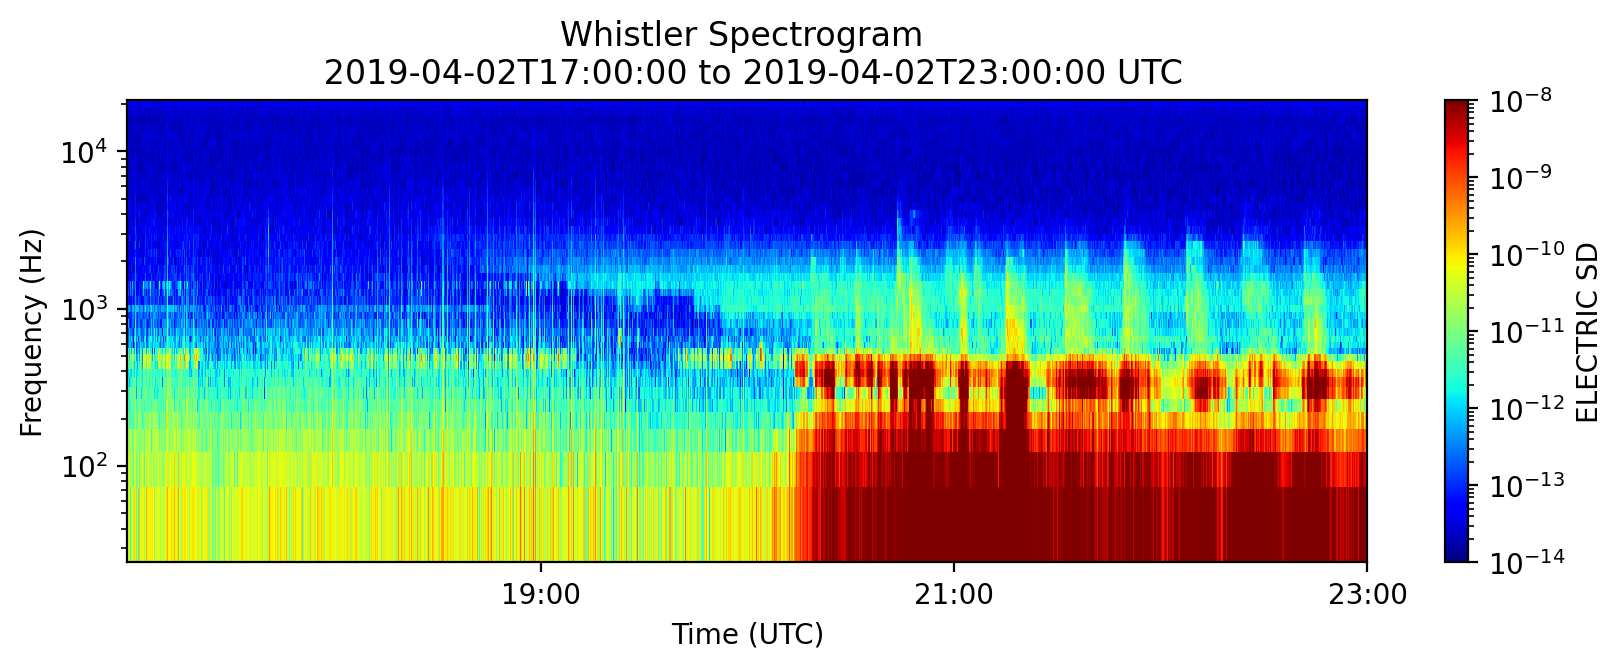

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.dates as mdates
from das2 import get_source
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL   = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME   = "2019-04-02T17:00:00"
END_TIME     = "2019-04-02T23:00:00"

# 1) Retrieve data (use only hect_data2 for Hectametric)
source = get_source(SERVER_URL)
whistler_data, kilometric_data, _, hect_data2 = source.get({
    'time': (START_TIME, END_TIME)
})

# Helper: extract time (1D), frequency (1D), and spec (2D: time x freq)
def extract_arrays(data):
    freq_arr = data['frequency']['center'].array
    freqs = freq_arr[0, :] if freq_arr.ndim > 1 else freq_arr
    time_arr = data['Time']['center'].array
    times = time_arr[:, 0] if time_arr.ndim > 1 else time_arr
    spec_arr = data['spec_dens']['center'].array
    spec = spec_arr.squeeze()
    if spec.shape[1] != freqs.size:
        spec = spec.T
    return times, freqs, spec

# Extract each dataset
times_hect, f_hect, s_hect = extract_arrays(hect_data2)
t_kilo,    f_kilo, s_kilo   = extract_arrays(kilometric_data)
t_whis,    f_whis, s_whis   = extract_arrays(whistler_data)

# —————————————————————————————————————————————
# 2) Compute dB above background for Hectametric & Kilometric

print(s_hect.shape)

# Hectametric: 10th‐percentile across time for each freq
bg_hect = np.percentile(s_hect, 10, axis=0, method='midpoint')       # shape (n_freq,)
eps_hect = np.nanmax(s_hect) * 1e-7
bg_hect = np.where(bg_hect <= 0, eps_hect, bg_hect)
dB_hect = 20 * np.log10(s_hect / bg_hect[None, :])  # still shape (time, freq)



# —————————————————————————————————————————————
# 3) Plot Hectametric dB spectrogram
fig_hect, ax_hect = plt.subplots(figsize=(10, 3), dpi=200)
mesh1 = ax_hect.pcolormesh(
    times_hect, f_hect, dB_hect.T,
    cmap='jet', shading='nearest', vmin=-5, vmax=25
)
ax_hect.set_yscale('log')
ax_hect.set_ylim(3e6, 40e6)
ax_hect.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_hect.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_hect.set_xlabel('Time (UTC)')
ax_hect.set_ylabel('Frequency (Hz)')
ax_hect.set_title(f'Hectametric Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar1 = fig_hect.colorbar(mesh1, ax=ax_hect, label='dB Above Background')
plt.show()

# —————————————————————————————————————————————
# 4) Plot Kilometric dB spectrogram
fig_kilo, ax_kilo = plt.subplots(figsize=(10, 3), dpi=200)
mesh2 = ax_kilo.pcolormesh(
    t_kilo, f_kilo, s_kilo.T,
    cmap='jet', shading='auto',
    norm=LogNorm(vmin=3e-15, vmax=3e-13)
)
ax_kilo.set_yscale('log')
ax_kilo.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_kilo.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_kilo.set_xlabel('Time (UTC)')
ax_kilo.set_ylabel('Frequency (Hz)')
ax_kilo.set_title(f'Kilometric Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar2 = fig_kilo.colorbar(mesh2, ax=ax_kilo, label='Electric SD')
plt.show()

# —————————————————————————————————————————————
# 5) (Optional) Whistler still in raw units
fig_whis, ax_whis = plt.subplots(figsize=(10, 3), dpi=200)
mesh3 = ax_whis.pcolormesh(
    t_whis, f_whis, s_whis.T,
    norm=LogNorm(vmin=1e-14, vmax=1e-8),
    cmap='jet', shading='auto'
)
ax_whis.set_yscale('log')
ax_whis.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax_whis.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_whis.set_xlabel('Time (UTC)')
ax_whis.set_ylabel('Frequency (Hz)')
ax_whis.set_title(f'Whistler Spectrogram \n {START_TIME} to {END_TIME} UTC')
cbar3 = fig_whis.colorbar(mesh3, ax=ax_whis, label='ELECTRIC SD')
plt.show()


/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/pdr/bit_handling.py:174: UserWarning: Data type LSB_UNSIGNED_INTEGER incompatible for bit column. Changing to MSB_BIT_STRING.
  warnings.warn(
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_32366/2549984995.py:108: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(cube, axis=2)    # (T, 64)
/var/folders/fz/cnqc4h596ll_2kqzb_kkg3x40000gn/T/ipykernel_32366/2549984995.py:368: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved → Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_segment_analysis.png


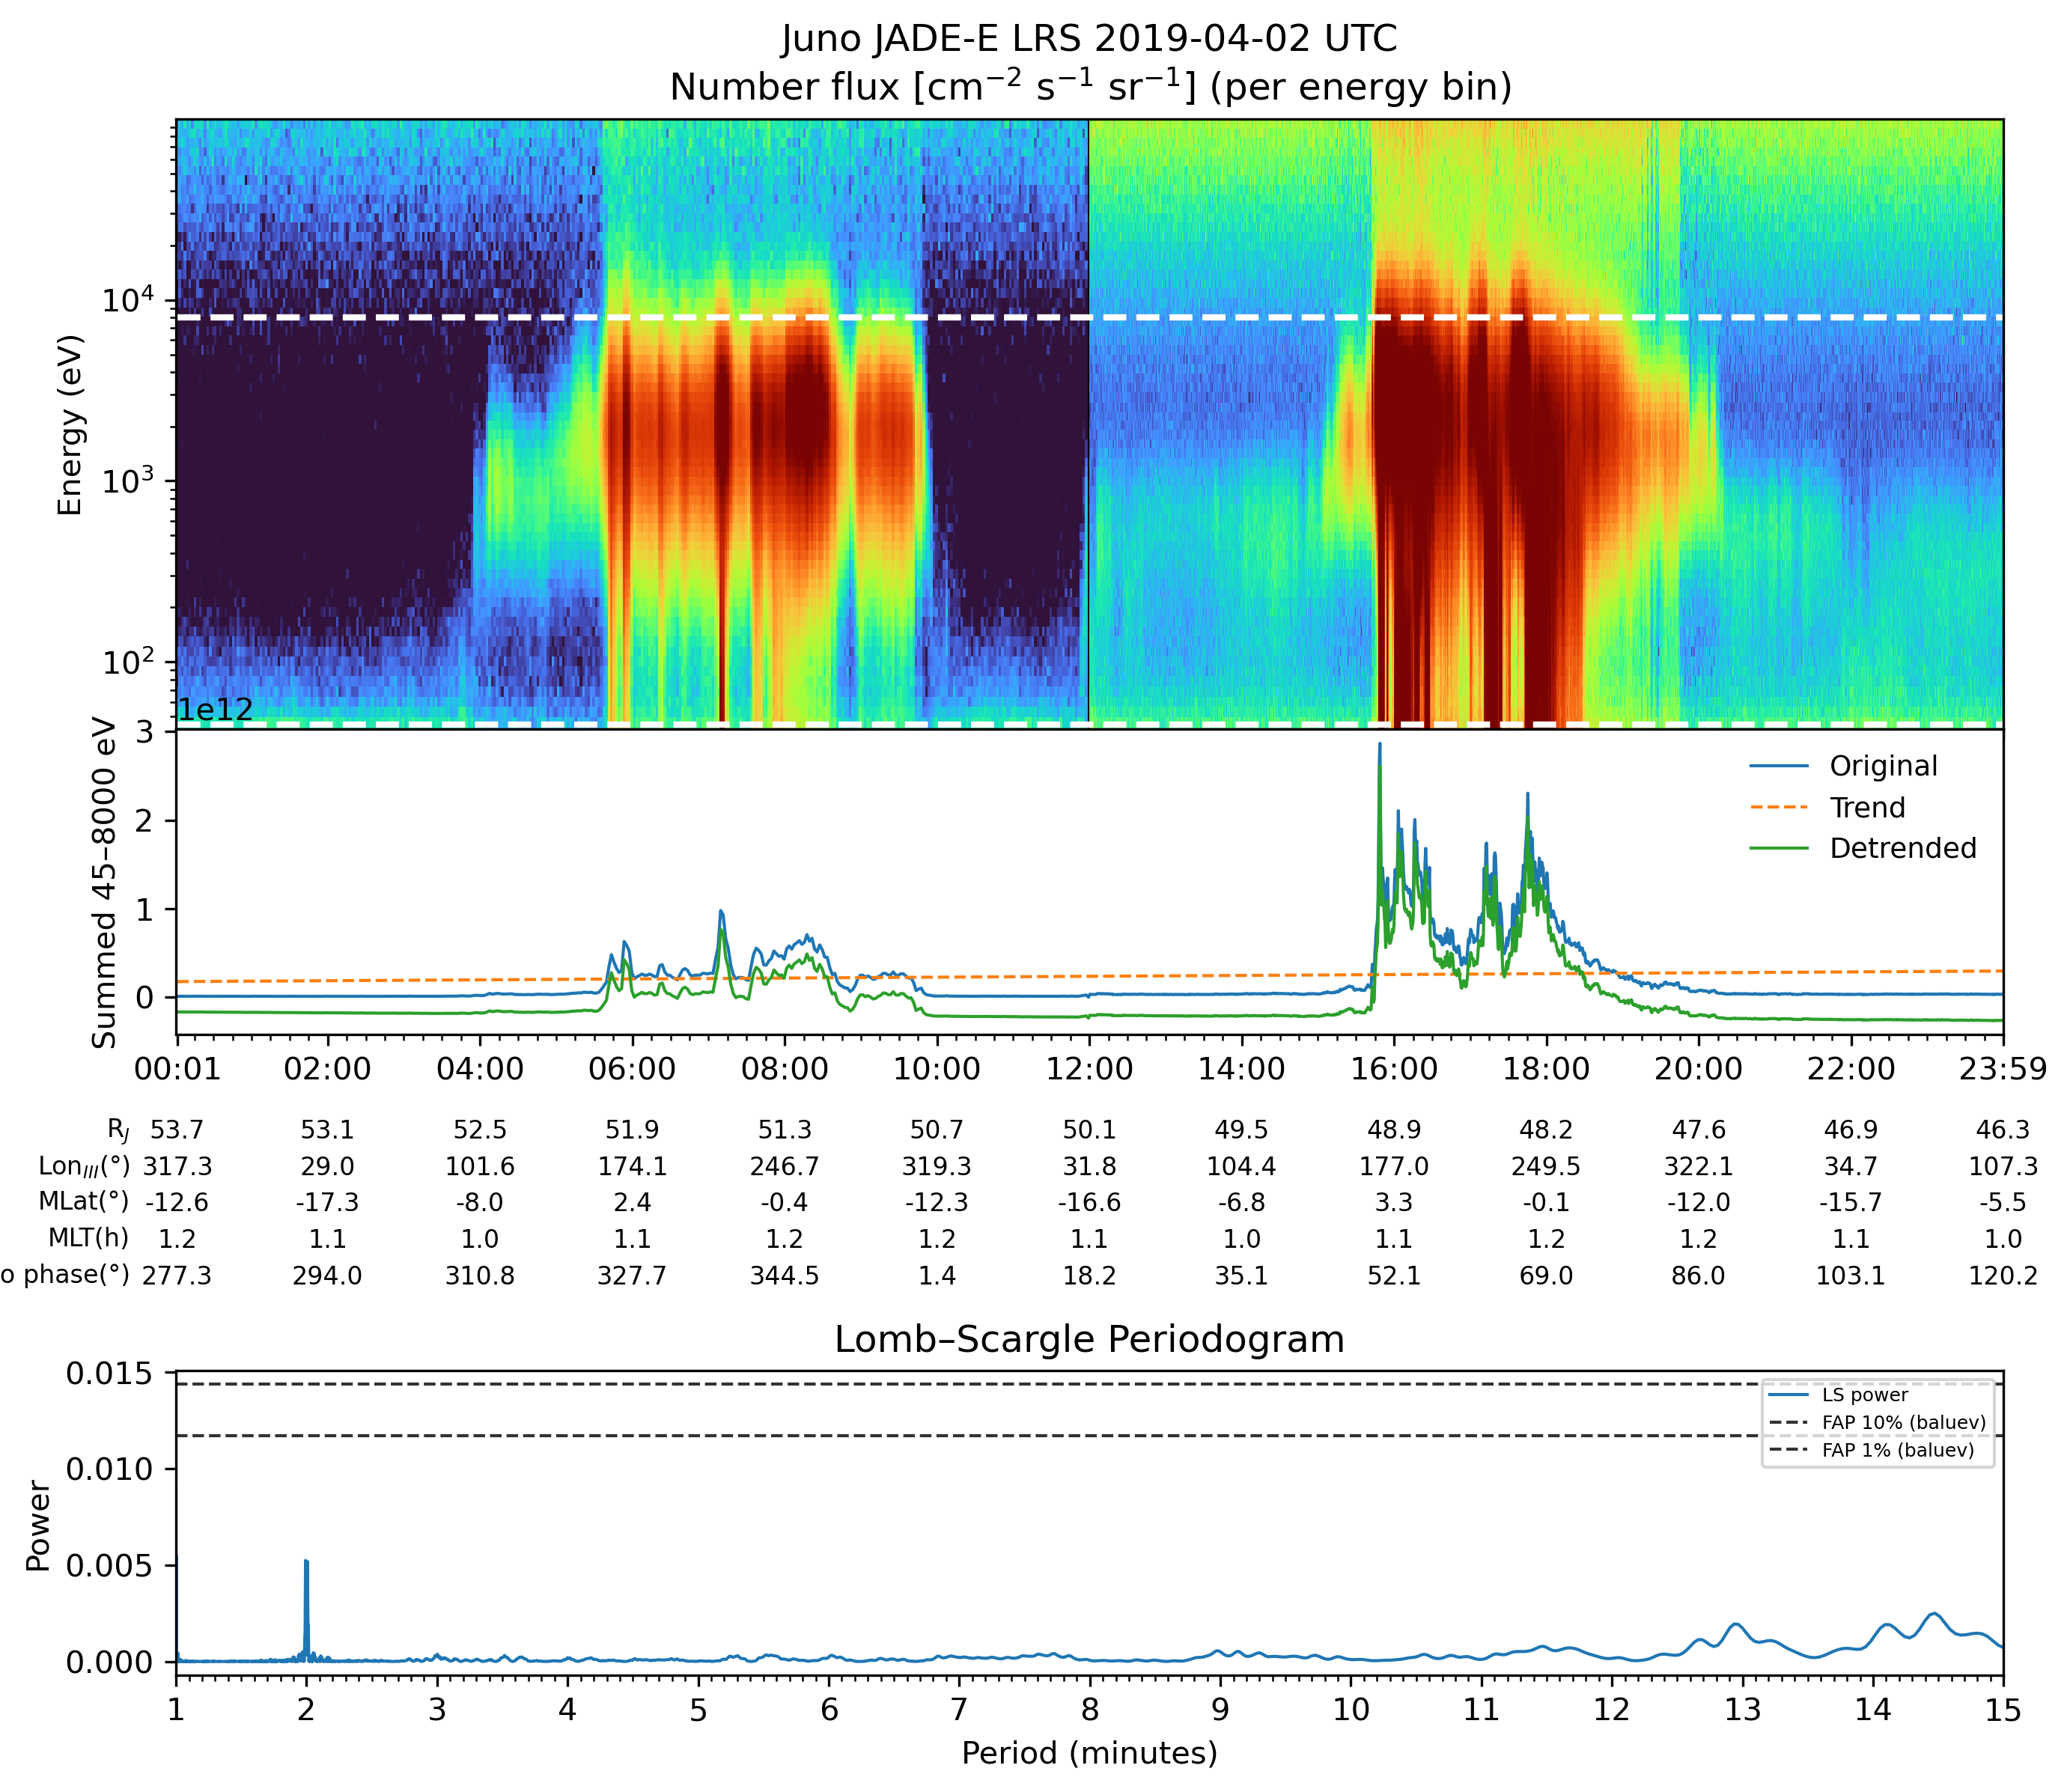

Saved f_pe series:
  Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_fpe_time_khz.npy
  Segment Analysis Figures/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01_fpe_time_khz.csv
n_e stats [cm^-3]: median=443, min=115, max=3.71e+04
f_pe stats [Hz]: median=1.89e+05, min=9.63e+04, max=1.73e+06


In [ ]:
# ================================================================
# JADE-E (PDS3 via pdr) → Segment Analysis + n_e(t) & f_pe(t)
#  - Spectrogram (log) with two horizontal energy lines
#  - Sum between lines → detrend (linear) + residual
#  - Ephemeris rows (Rj, LonIII, MLat, MLT, Io phase)
#  - Lomb-Scargle periodogram + peak picking in a period window
#  - Plot 10% and 1% FAP thresholds on periodogram plot
#  - Local electron density from JADE-E number flux (per bin) → f_pe(t)
# ================================================================

import os

# (Optional but often helpful on Apple/macOS to avoid CPU oversubscription
#  when using BLAS/FFT libs)
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks

from astropy.timeseries import LombScargle
from das2 import get_source
import pdr

# ---------------- User config ----------------
LBL_PATH        = "Data_Files/20190402 All Data/JAD_L50_LRS_ELC_ANY_DEF_2019092_V01.LBL"
OUT_DIR         = "Segment Analysis Figures"
os.makedirs(OUT_DIR, exist_ok=True)

START_TIME   = "2019-04-02T00:00:00"
END_TIME     = "2019-04-03T00:00:00"

ENERGY_MIN_EV   = 45.0
ENERGY_MAX_EV   = 8000.0

# Periodogram settings (minutes)
PERIOD_MIN      = 1
PERIOD_MAX      = 15
PEAK_DETECT_MIN = 2.5
NUM_PEAKS       = 4

# Lomb–Scargle frequency grid resolution
LS_NFREQ        = 5000   # increase if you want denser sampling

# Hard-coded JADE-E 64 energy centers (eV)
ENERGY_BINS_EV = np.array([
    4.5731E+001, 5.3296E+001, 6.0349E+001, 6.8611E+001, 7.7419E+001,
    8.9858E+001, 1.0039E+002, 1.1494E+002, 1.2908E+002, 1.4807E+002,
    1.6538E+002, 1.8943E+002, 2.1210E+002, 2.4241E+002, 2.7057E+002,
    3.0856E+002, 3.4290E+002, 3.9006E+002, 4.3681E+002, 4.9299E+002,
    5.5223E+002, 6.2153E+002, 6.9798E+002, 7.8441E+002, 8.8190E+002,
    9.9458E+002, 1.1175E+003, 1.2632E+003, 1.4210E+003, 1.6066E+003,
    1.8068E+003, 2.0410E+003, 2.2617E+003, 2.5464E+003, 2.9011E+003,
    3.2921E+003, 3.7061E+003, 4.1751E+003, 4.7001E+003, 5.2996E+003,
    5.9765E+003, 6.7664E+003, 7.6124E+003, 8.5852E+003, 9.6487E+003,
    1.0927E+004, 1.2282E+004, 1.3872E+004, 1.5623E+004, 1.7610E+004,
    1.9783E+004, 2.2346E+004, 2.5209E+004, 2.8414E+004, 3.2039E+004,
    3.6123E+004, 4.0668E+004, 4.5886E+004, 5.1684E+004, 5.8298E+004,
    6.5677E+004, 7.4021E+004, 8.3346E+004, 9.3975E+004
], dtype=float)

N_E, N_LOOK = 64, 48
N_COLS = N_E * N_LOOK


# ---------------- Helpers ----------------
def energy_edges_from_centers(e):
    """Geometric midpoints; extrapolated outer edges."""
    e = np.asarray(e, float)
    mids = np.sqrt(e[:-1] * e[1:])
    return np.concatenate([[e[0]**2 / mids[0]], mids, [e[-1]**2 / mids[-1]]])


def load_jade_cube(lbl_path):
    ds = pdr.read(lbl_path)
    df = ds["TABLE"]

    t_lo = pd.to_datetime(df["DIM0_UTC_LOWER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)
    t_hi = pd.to_datetime(df["DIM0_UTC_UPPER"].astype(str), format="%Y-%jT%H:%M:%S.%f", utc=False)

    pat = re.compile(r"^DATA_(\d+)$", re.IGNORECASE)
    pairs = []
    for c in df.columns:
        m = pat.match(str(c))
        if m:
            pairs.append((int(m.group(1)), c))
    pairs.sort(key=lambda x: x[0])
    data_cols = [c for _, c in pairs]
    if len(data_cols) != N_COLS:
        raise ValueError(f"Expected {N_COLS} DATA columns, got {len(data_cols)}")

    raw = df[data_cols].to_numpy(dtype=float)
    raw[raw <= -9.0e5] = np.nan

    nt = len(df)
    cube = raw.reshape(nt, N_E, N_LOOK)  # (T, 64, 48)
    # some rows/energies may be all-NaN across look; that's OK
    Z_mean = np.nanmean(cube, axis=2)    # (T, 64)

    mask = t_lo.notna() & t_hi.notna()
    t_lo = t_lo[mask].reset_index(drop=True)
    t_hi = t_hi[mask].reset_index(drop=True)
    Z_mean = Z_mean[mask.values, :]

    ord_idx = np.argsort(t_lo.values)
    t_lo = t_lo.iloc[ord_idx].reset_index(drop=True)
    t_hi = t_hi.iloc[ord_idx].reset_index(drop=True)
    Z_mean = Z_mean[ord_idx, :]

    t_edges = pd.DatetimeIndex(np.concatenate([t_lo.values[:1], t_hi.values]))
    t_centers = t_lo + (t_hi - t_lo) / 2

    sorter = np.argsort(ENERGY_BINS_EV)
    e_sorted = ENERGY_BINS_EV[sorter]
    Zp = Z_mean[:, sorter]
    e_edges = energy_edges_from_centers(e_sorted)

    return t_edges, t_centers, e_sorted, e_edges, Zp


def summarize_between_lines(e_sorted, Zp, emin_ev, emax_ev):
    mask_e = (e_sorted >= emin_ev) & (e_sorted <= emax_ev)
    if not np.any(mask_e):
        raise ValueError("Energy mask is empty; check ENERGY_MIN_EV/ENERGY_MAX_EV.")
    summed = np.nansum(Zp[:, mask_e], axis=1)
    return summed, mask_e


def _interpolate_nans_time(times_ns, y):
    """Time-based interpolation for NaNs (keeps sampling)."""
    y = np.asarray(y, float)
    if np.all(np.isfinite(y)):
        return y
    s = pd.Series(y, index=pd.to_datetime(times_ns))
    s = s.interpolate(method="time").bfill().ffill()
    return s.to_numpy(dtype=float)


# ---------------- Main figure ----------------
def make_segment_analysis_from_pds3(
    lbl_path=LBL_PATH,
    start_time=START_TIME,
    end_time=END_TIME,
    emin_ev=ENERGY_MIN_EV,
    emax_ev=ENERGY_MAX_EV,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    peak_detect_min=PEAK_DETECT_MIN,
    num_peaks=NUM_PEAKS,
    save_png=True
):
    # Load PDS3 + build arrays
    t_edges, t_centers, e_sorted, e_edges, Zp = load_jade_cube(lbl_path)

    # Window
    t0 = pd.to_datetime(start_time)
    t1 = pd.to_datetime(end_time)
    mask_t = (t_centers >= t0) & (t_centers <= t1)
    if not np.any(mask_t):
        raise ValueError("Time window selects no samples; check START_TIME/END_TIME.")

    times_win = t_centers[mask_t].to_numpy(dtype="datetime64[ns]")
    Z_win     = Zp[mask_t.values, :]

    # Sum between lines
    avg_counts, mask_e = summarize_between_lines(e_sorted, Z_win, emin_ev, emax_ev)
    avg_counts = _interpolate_nans_time(times_win, avg_counts)

    # Detrend linear
    t0c = times_win[0]
    t_sec = (times_win - t0c) / np.timedelta64(1, "s")
    if len(t_sec) < 4:
        raise ValueError("Too few samples in window for periodogram.")
    dt_s = float(np.median(np.diff(t_sec)))
    if not np.isfinite(dt_s) or dt_s <= 0:
        raise ValueError("Non-positive or invalid cadence; check time ordering/data gaps.")

    coeff = np.polyfit(t_sec, avg_counts, 1)
    trend = np.polyval(coeff, t_sec)
    residual = avg_counts - trend
    residual = residual - np.mean(residual)  # remove DC

    # ------------- Lomb–Scargle periodogram in the requested band -------------
    # frequency bounds corresponding to the PERIOD window
    fmin = 1.0 / (period_max * 60.0)  # Hz
    fmax = 1.0 / (period_min * 60.0)  # Hz
    freq = np.linspace(fmin, fmax, LS_NFREQ)

    # Use explicit normalization so FAP is well-defined within astropy’s conventions
    ls = LombScargle(t_sec, residual, normalization="standard", center_data=False)
    power = ls.power(freq)

    periods_mask = (1.0 / freq) / 60.0  # minutes (monotonic decreasing)
    # Sort so x-axis increases left→right (period_min to period_max)
    order = np.argsort(periods_mask)
    periods_ls = periods_mask[order]
    power_ls   = power[order]

    # Peak picking in LS power
    peaks, _ = find_peaks(power_ls)
    if peaks.size:
        sort_idx = np.argsort(power_ls[peaks])
        sel = peaks[sort_idx][-num_peaks:]
        sel = np.sort(sel)

        peak_periods = periods_ls[sel]
        peak_powers  = power_ls[sel]

        keep = peak_periods >= peak_detect_min
        peak_periods = peak_periods[keep]
        peak_powers  = peak_powers[keep]

        o2 = np.argsort(peak_periods)
        peak_periods = peak_periods[o2]
        peak_powers  = peak_powers[o2]
    else:
        peak_periods = np.array([], dtype=float)
        peak_powers  = np.array([], dtype=float)

    # FAP thresholds (global over the searched frequency range)
    # method="baluev" is usually a good analytic default; if it errors, fall back.
    try:
        thr_10 = ls.false_alarm_level(0.10, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="baluev",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "baluev"
    except Exception:
        thr_10 = ls.false_alarm_level(0.10, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        thr_01 = ls.false_alarm_level(0.01, method="naive",
                                     minimum_frequency=fmin, maximum_frequency=fmax)
        fap_method = "naive"

    # ------------- Plot (unchanged layout except LS replaces FFT panel) -------------
    basename = os.path.splitext(os.path.basename(lbl_path))[0]
    fig = plt.figure(figsize=(10.5, 9), dpi=300)
    outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.55)
    inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[2, 1], hspace=0.0)

    ax_spec = fig.add_subplot(inner_gs[0])
    ax_avg  = fig.add_subplot(inner_gs[1], sharex=ax_spec)
    ax_fft  = fig.add_subplot(outer_gs[1])  # keep name to avoid changing other code structure

    # Spectrogram edges for the window
    idx0 = np.where(t_centers.to_numpy() >= times_win[0])[0][0]
    idx1 = np.where(t_centers.to_numpy() <= times_win[-1])[0][-1]
    t_edges_win = t_edges[idx0: idx1 + 2]

    Zpos = Z_win[np.isfinite(Z_win) & (Z_win > 0)]
    if Zpos.size == 0:
        raise RuntimeError("No positive values to plot.")
    vmin, vmax = np.nanpercentile(Zpos, [5, 95])
    vmin = max(vmin, np.nextafter(0.0, 1.0))

    pcm = ax_spec.pcolormesh(
        t_edges_win, e_edges, Z_win.T, shading="auto",
        norm=LogNorm(vmin=vmin, vmax=vmax), cmap="turbo"
    )
    ax_spec.set_yscale("log")
    ax_spec.set_facecolor("black")
    ax_spec.plot([times_win[0], times_win[-1]], [emin_ev, emin_ev], "--w", lw=2)
    ax_spec.plot([times_win[0], times_win[-1]], [emax_ev, emax_ev], "--w", lw=2)
    ax_spec.set_ylabel("Energy (eV)")
    ax_spec.set_title(
        f"Juno JADE-E LRS {pd.to_datetime(START_TIME).strftime('%Y-%m-%d')} UTC\n"
        + r"Number flux [$\mathrm{cm^{-2}\ s^{-1}\ sr^{-1}}$] (per energy bin)"
    )
    ax_spec.tick_params(labelbottom=False)
    #fig.colorbar(pcm, ax=ax_spec, pad=0.01, label="Number flux (per bin)")

    # Summed series + trend + residual
    ax_avg.plot(times_win, avg_counts, label="Original", color="C0", lw=1.0)
    ax_avg.plot(times_win, trend, linestyle="--", color="C1", label="Trend", lw=1.0)
    ax_avg.plot(times_win, residual, color="C2", label="Detrended", lw=1.0)
    ax_avg.set_ylabel(f"Summed {emin_ev:.0f}–{emax_ev:.0f} eV")
    ax_avg.legend(frameon=False, fontsize=9)

    # Ticks
    total_hours = (times_win[-1] - times_win[0]) / np.timedelta64(1, "h")
    tick_interval_h = 1 if total_hours <= 12 else 2
    eph_step = np.timedelta64(30, "m") if total_hours <= 4 else np.timedelta64(int(tick_interval_h), "h")

    t0h = times_win[0].astype("datetime64[h]")
    t1h = times_win[-1].astype("datetime64[h]") + np.timedelta64(1, "h")
    maj = np.arange(t0h, t1h, eph_step)
    all_ticks = np.unique(np.concatenate(([times_win[0]], maj, [times_win[-1]])))
    py_ticks  = [pd.to_datetime(t).to_pydatetime() for t in all_ticks]
    tick_nums = mdates.date2num(py_ticks)

    ax_avg.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_avg.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_avg.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))
    plt.setp(ax_avg.get_xticklabels(which="major"), rotation=0)

    # Ephemeris rows (unchanged)
    eph_src = get_source("tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2")
    ds_eph = eph_src.get({"time": (START_TIME, END_TIME, int(max(1, round(dt_s))))})[0]

    eph_t  = ds_eph["time"]["center"].array
    rad    = ds_eph["radius"]["center"].array
    lon3   = ds_eph["long"]["center"].array
    mlatE  = ds_eph["mlat"]["center"].array
    mltE   = ds_eph["mlt"]["center"].array
    ioE    = ds_eph["io_phase"]["center"].array
    if getattr(mltE, "dtype", None) is not None and mltE.dtype.kind == "m":
        mltE = (mltE / np.timedelta64(1, "h")).astype(float)

    row_lbls   = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)", "Io phase(°)"]
    row_arrays = [rad, lon3, mlatE, mltE, ioE]
    row_spacing = 0.12

    idxs = [int(np.argmin(np.abs(eph_t - np.datetime64(t)))) for t in all_ticks]
    for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
        off = -row_spacing * (j + 2)
        sax = ax_avg.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
        sax.xaxis.set_major_locator(FixedLocator(tick_nums))
        vals = arr[idxs]
        sax.set_xticklabels([f"{float(v):.1f}" for v in vals], rotation=0, va="top", fontsize=8)
        sax.spines["bottom"].set_visible(False)
        sax.tick_params(axis="x", length=0)
        sax.xaxis.set_ticks_position("bottom")
        sax.xaxis.set_label_position("bottom")
        txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc="left")
        txt.set_x(-0.025)
        txt.set_ha("right")

    # (d) Lomb–Scargle plot + FAP lines + peak lines (kept styling similar)
    ls_line, = ax_fft.plot(periods_ls, power_ls, color="C0", linewidth=1, label="LS power")

    # FAP thresholds
    ax_fft.axhline(thr_10, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 10% ({fap_method})")
    ax_fft.axhline(thr_01, ls="--", lw=1, color="k", alpha=0.8, label=f"FAP 1% ({fap_method})")

    for p in peak_periods:
        ax_fft.axvline(p, ls="--", color="red", lw=1)
        ax_fft.text(
            p, -0.05, f"{p:.2f}",
            transform=ax_fft.get_xaxis_transform(),
            rotation=90, va="top", ha="center",
            color="red", fontsize=7
        )

    ax_fft.set_xlim(period_min, period_max)
    ax_fft.set_xlabel("Period (minutes)")
    ax_fft.set_ylabel("Power")
    ax_fft.set_title("Lomb–Scargle Periodogram")
    ax_fft.xaxis.set_major_locator(MultipleLocator(1))
    ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

    ax_fft.legend(loc="upper right", frameon=True, fontsize=6, title_fontsize=7)

    # align X ticks on spectrogram
    ax_spec.xaxis.set_major_locator(FixedLocator(tick_nums))
    ax_spec.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_spec.xaxis.set_minor_locator(mdates.MinuteLocator(interval=15))

    fig.tight_layout()

    if save_png:
        out = os.path.join(OUT_DIR, f"{basename}_segment_analysis.png")
        fig.savefig(out, dpi=300, bbox_inches="tight")
        print(f"Saved → {out}")

    plt.show()

    # ===========================================
    # POST: n_e(t) from JADE-E number flux (per bin) → f_pe(t)
    # ===========================================
    E_ev   = e_sorted.astype(float)
    dE_ev  = np.diff(e_edges).astype(float)  # (64,)

    assert Z_win.shape[1] == dE_ev.size == e_sorted.size == 64, \
        f"Shape mismatch: Z_win {Z_win.shape}, dE {dE_ev.size}, e_sorted {e_sorted.size}"

    j_per_eV = Z_win / dE_ev[np.newaxis, :]

    me = 9.10938356e-31
    qe = 1.602176634e-19
    v_cms = np.sqrt(2.0 * (E_ev * qe) / me) * 100.0

    emask = (E_ev >= 50.0) & (E_ev <= 20000.0)
    integrand = j_per_eV[:, emask] / v_cms[np.newaxis, emask]
    ne_cm3 = 4.0 * np.pi * np.trapz(integrand, x=E_ev[emask], axis=1)

    fpe_hz  = 8980.0 * np.sqrt(np.clip(ne_cm3, 0, None))


    t_unix = (times_win.astype('datetime64[ns]').astype('int64') / 1e9).astype(float)
    fpe_2d = np.column_stack([t_unix, fpe_hz])

    base = os.path.splitext(os.path.basename(lbl_path))[0]
    out_npy = os.path.join(OUT_DIR, f"{base}_fpe_time_khz.npy")
    out_csv = os.path.join(OUT_DIR, f"{base}_fpe_time_khz.csv")
    np.save(out_npy, fpe_2d)
    np.savetxt(out_csv, fpe_2d, delimiter=",", header="unix_time_s,f_pe_kHz", comments="")

    print(f"Saved f_pe series:\n  {out_npy}\n  {out_csv}")
    print(f"n_e stats [cm^-3]: median={np.nanmedian(ne_cm3):.3g}, "
          f"min={np.nanmin(ne_cm3):.3g}, max={np.nanmax(ne_cm3):.3g}")
    print(f"f_pe stats [Hz]: median={np.nanmedian(fpe_hz):.3g}, "
          f"min={np.nanmin(fpe_hz):.3g}, max={np.nanmax(fpe_hz):.3g}")

    return fpe_hz, t_unix
# ---------------- Run ----------------
if __name__ == "__main__":
    fpe_hz, t_fpe_input = make_segment_analysis_from_pds3()

/opt/anaconda3/envs/das2env/lib/python3.9/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


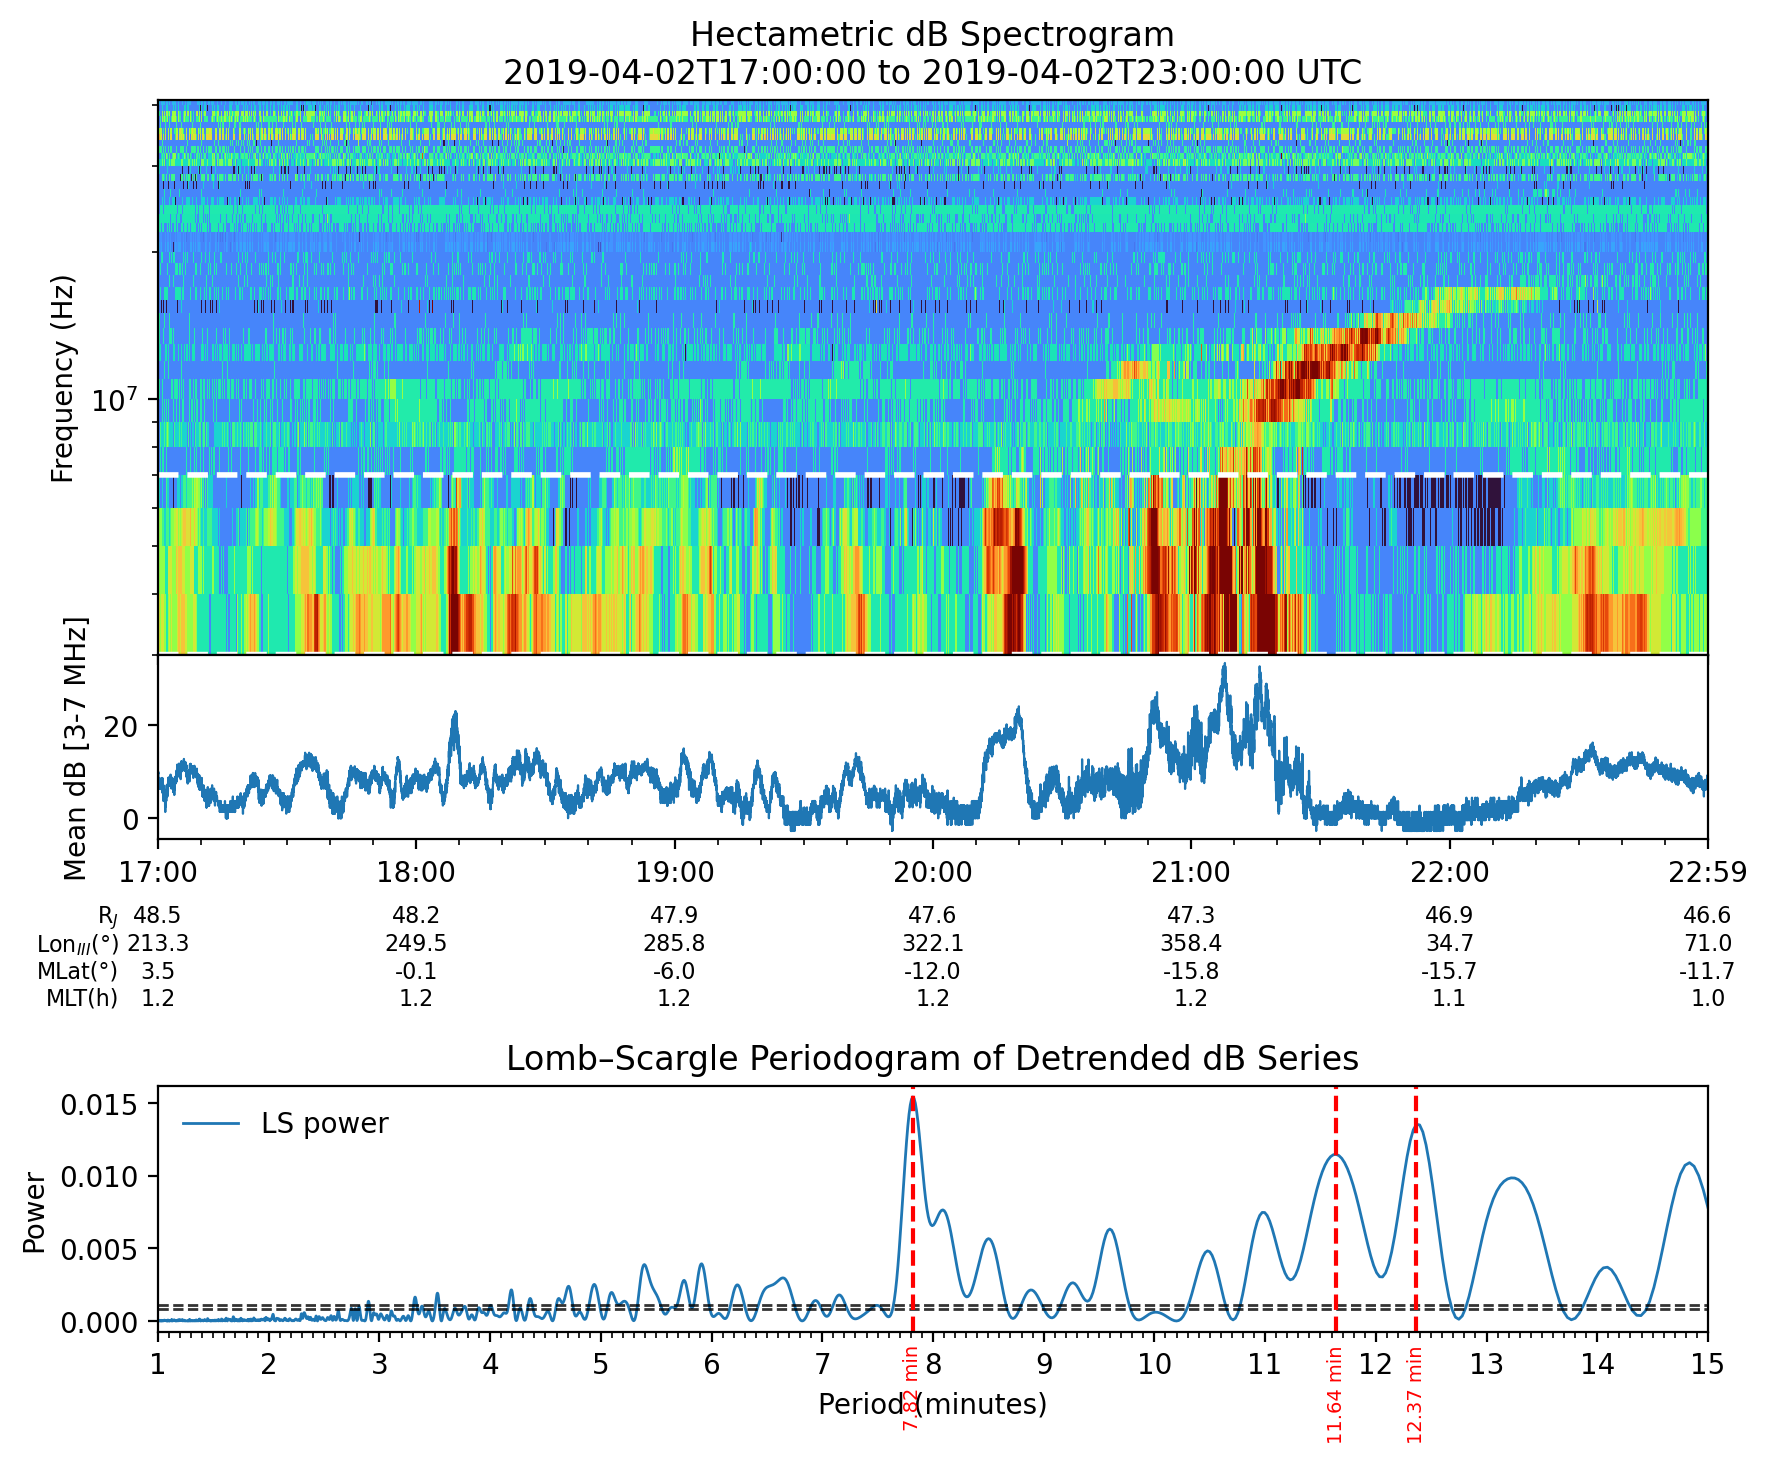

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from scipy.signal import find_peaks
from das2 import get_source
from matplotlib.gridspec import GridSpec
from astropy.timeseries import LombScargle

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL   = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME   = "2019-04-02T17:00:00"
END_TIME     = "2019-04-02T23:00:00"

# Hectametric dB spectrogram color limits
DB_VMIN      = -5
DB_VMAX      = 25

# Frequency band for PSD (Hz)
HECT_MIN     = 3e6    # 3 MHz
HECT_MAX     = 7e6    # 7 MHz

# Periodogram parameters
PERIOD_MIN      = 1      # minutes
PERIOD_MAX      = 15     # minutes
PEAK_DETECT_MIN = 2.5    # only mark peaks ≥ this period (min)
NUM_PEAKS       = 3      # number of top peaks to label

# Lomb–Scargle frequency grid resolution
LS_NFREQ        = 5000   # increase if you want denser sampling

# —————————————————————————————————————————————
# 1) Fetch Hectametric data
source = get_source(SERVER_URL)
_, _, _, hect = source.get({'time': (START_TIME, END_TIME)})

# 2) Extract arrays
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0, :] if f_arr.ndim > 1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:, 0] if t_arr.ndim > 1 else t_arr
    S = d['spec_dens']['center'].array.squeeze()
    if S.shape[1] != freqs.size:
        S = S.T
    return np.array(times, dtype='datetime64[ms]'), freqs, S

times, freqs, spec = extract_arrays(hect)

# 2a) decide tick spacing
total_hours     = (times[-1] - times[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2

# 3) dB above 10th-percentile background
S_clean = spec.astype(float)
mask_bad = (S_clean <= 0) | (~np.isfinite(S_clean))
S_clean[mask_bad] = np.nan
bg  = np.nanpercentile(S_clean, 10, axis=0)
eps = np.nanmax(S_clean) * 1e-6
bg  = np.where(bg <= 0, eps, bg)
dB_hect = 20 * np.log10(spec / bg[None, :])

# 4) Band-average dB time series
band_mask = (freqs >= HECT_MIN) & (freqs <= HECT_MAX)
dB_band   = np.nanmean(dB_hect[:, band_mask], axis=1)

# 5) Time in sec for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))

# 6) Detrend & variance (keep these as you had them)
coeff    = np.polyfit(t_sec, dB_band, 1)
trend    = np.polyval(coeff, t_sec)
residual = dB_band - trend

# 7) Lomb–Scargle periodogram in PERIOD_MIN..PERIOD_MAX
resid0 = residual - np.nanmean(residual)

fmin = 1.0 / (PERIOD_MAX * 60.0)   # Hz
fmax = 1.0 / (PERIOD_MIN * 60.0)   # Hz
freq = np.linspace(fmin, fmax, LS_NFREQ)

ls = LombScargle(t_sec, resid0, normalization="standard", center_data=False)
power = ls.power(freq)

# Convert to period (minutes) and sort increasing for plotting
periods_ls = (1.0 / freq) / 60.0
order = np.argsort(periods_ls)
periods_ls = periods_ls[order]
power_ls   = power[order]

p_mask = (periods_ls >= PERIOD_MIN) & (periods_ls <= PERIOD_MAX)
periods_m = periods_ls[p_mask]
pow_m     = power_ls[p_mask]

# Peak detection (same approach)
peaks, _ = find_peaks(pow_m)
if peaks.size > 0:
    sel = peaks[np.argsort(pow_m[peaks])][-NUM_PEAKS:]
    peak_periods = periods_m[sel]
    peak_periods = peak_periods[peak_periods >= PEAK_DETECT_MIN]
else:
    peak_periods = np.array([])

# FAP thresholds (10% and 1%) over the searched frequency range
try:
    thr_10 = ls.false_alarm_level(0.10, method="baluev",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    thr_01 = ls.false_alarm_level(0.01, method="baluev",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    fap_method = "baluev"
except Exception:
    thr_10 = ls.false_alarm_level(0.10, method="naive",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    thr_01 = ls.false_alarm_level(0.01, method="naive",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    fap_method = "naive"

# ─── Plot: nested GridSpec ─────────────────────────────────────────────────
fig = plt.figure(figsize=(10, 8), dpi=200)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[3, 1], hspace=0.5)

# top compound: spectrogram + band-avg
inner_gs = outer_gs[0].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
ax_spec  = fig.add_subplot(inner_gs[0])
ax_ts    = fig.add_subplot(inner_gs[1], sharex=ax_spec)

# bottom: periodogram
ax_fft   = fig.add_subplot(outer_gs[1])

# (a) dB spectrogram
pcm = ax_spec.pcolormesh(
    times, freqs, dB_hect.T,
    cmap='turbo', shading='nearest',
    vmin=DB_VMIN, vmax=DB_VMAX
)
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [HECT_MIN]*len(times), '--w', lw=2)
ax_spec.plot(times, [HECT_MAX]*len(times), '--w', lw=2)
ax_spec.set_ylabel('Frequency (Hz)')
ax_spec.set_title(f'Hectametric dB Spectrogram\n{START_TIME} to {END_TIME} UTC')
ax_spec.tick_params(labelbottom=False)

# (b) Band-averaged dB
ax_ts.plot(times, dB_band, color='C0', linewidth=0.8)
ax_ts.set_ylabel(f'Mean dB [{HECT_MIN/1e6:.0f}-{HECT_MAX/1e6:.0f} MHz]')
ax_ts.set_xlim(times[0], times[-1])

# build unified tick list (endpoints + majors)
t0h       = times[0].astype('datetime64[h]')
t1h       = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj       = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))
all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))
py_ticks  = [t.tolist() for t in all_ticks]
all_nums  = mdates.date2num(py_ticks)

fmt = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(FixedLocator(all_nums))
ax_ts.xaxis.set_major_formatter(fmt)
ax_ts.xaxis.set_minor_locator(mdates.MinuteLocator(interval=10))

# ─── Ephemeris rows under band-avg ──────────────────────────────────────────
eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array
if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays  = [rad, lon3, mlatE, mltE]
row_spacing = 0.15

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
    sax.xaxis.set_major_locator(FixedLocator(all_nums))
    vals = arr[[np.argmin(np.abs(times - t64)) for t64 in all_ticks]]
    sax.set_xticklabels([f"{v:.1f}" for v in vals],
                        rotation=0, va='top', fontsize=8)
    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.025)
    txt.set_ha('right')

# (c) Lomb–Scargle Periodogram (replaces FFT)
ax_fft.plot(periods_m, pow_m, color='C0', linewidth=1, label='LS power')

# FAP lines
ax_fft.axhline(thr_10, ls='--', lw=1, color='k', alpha=0.8)
ax_fft.axhline(thr_01, ls='--', lw=1, color='k', alpha=0.8)

for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p, -0.05, f'{p:.2f} min',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90, va='top', ha='center',
        color='red', fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('Lomb–Scargle Periodogram of Detrended dB Series')
ax_fft.legend(loc='upper left', frameon=False)
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()

tick_interval_h = 2
f_pe range (Hz): 9.63e+04 – 1.73e+06
fz points: 86303 | fuhr points: 86303


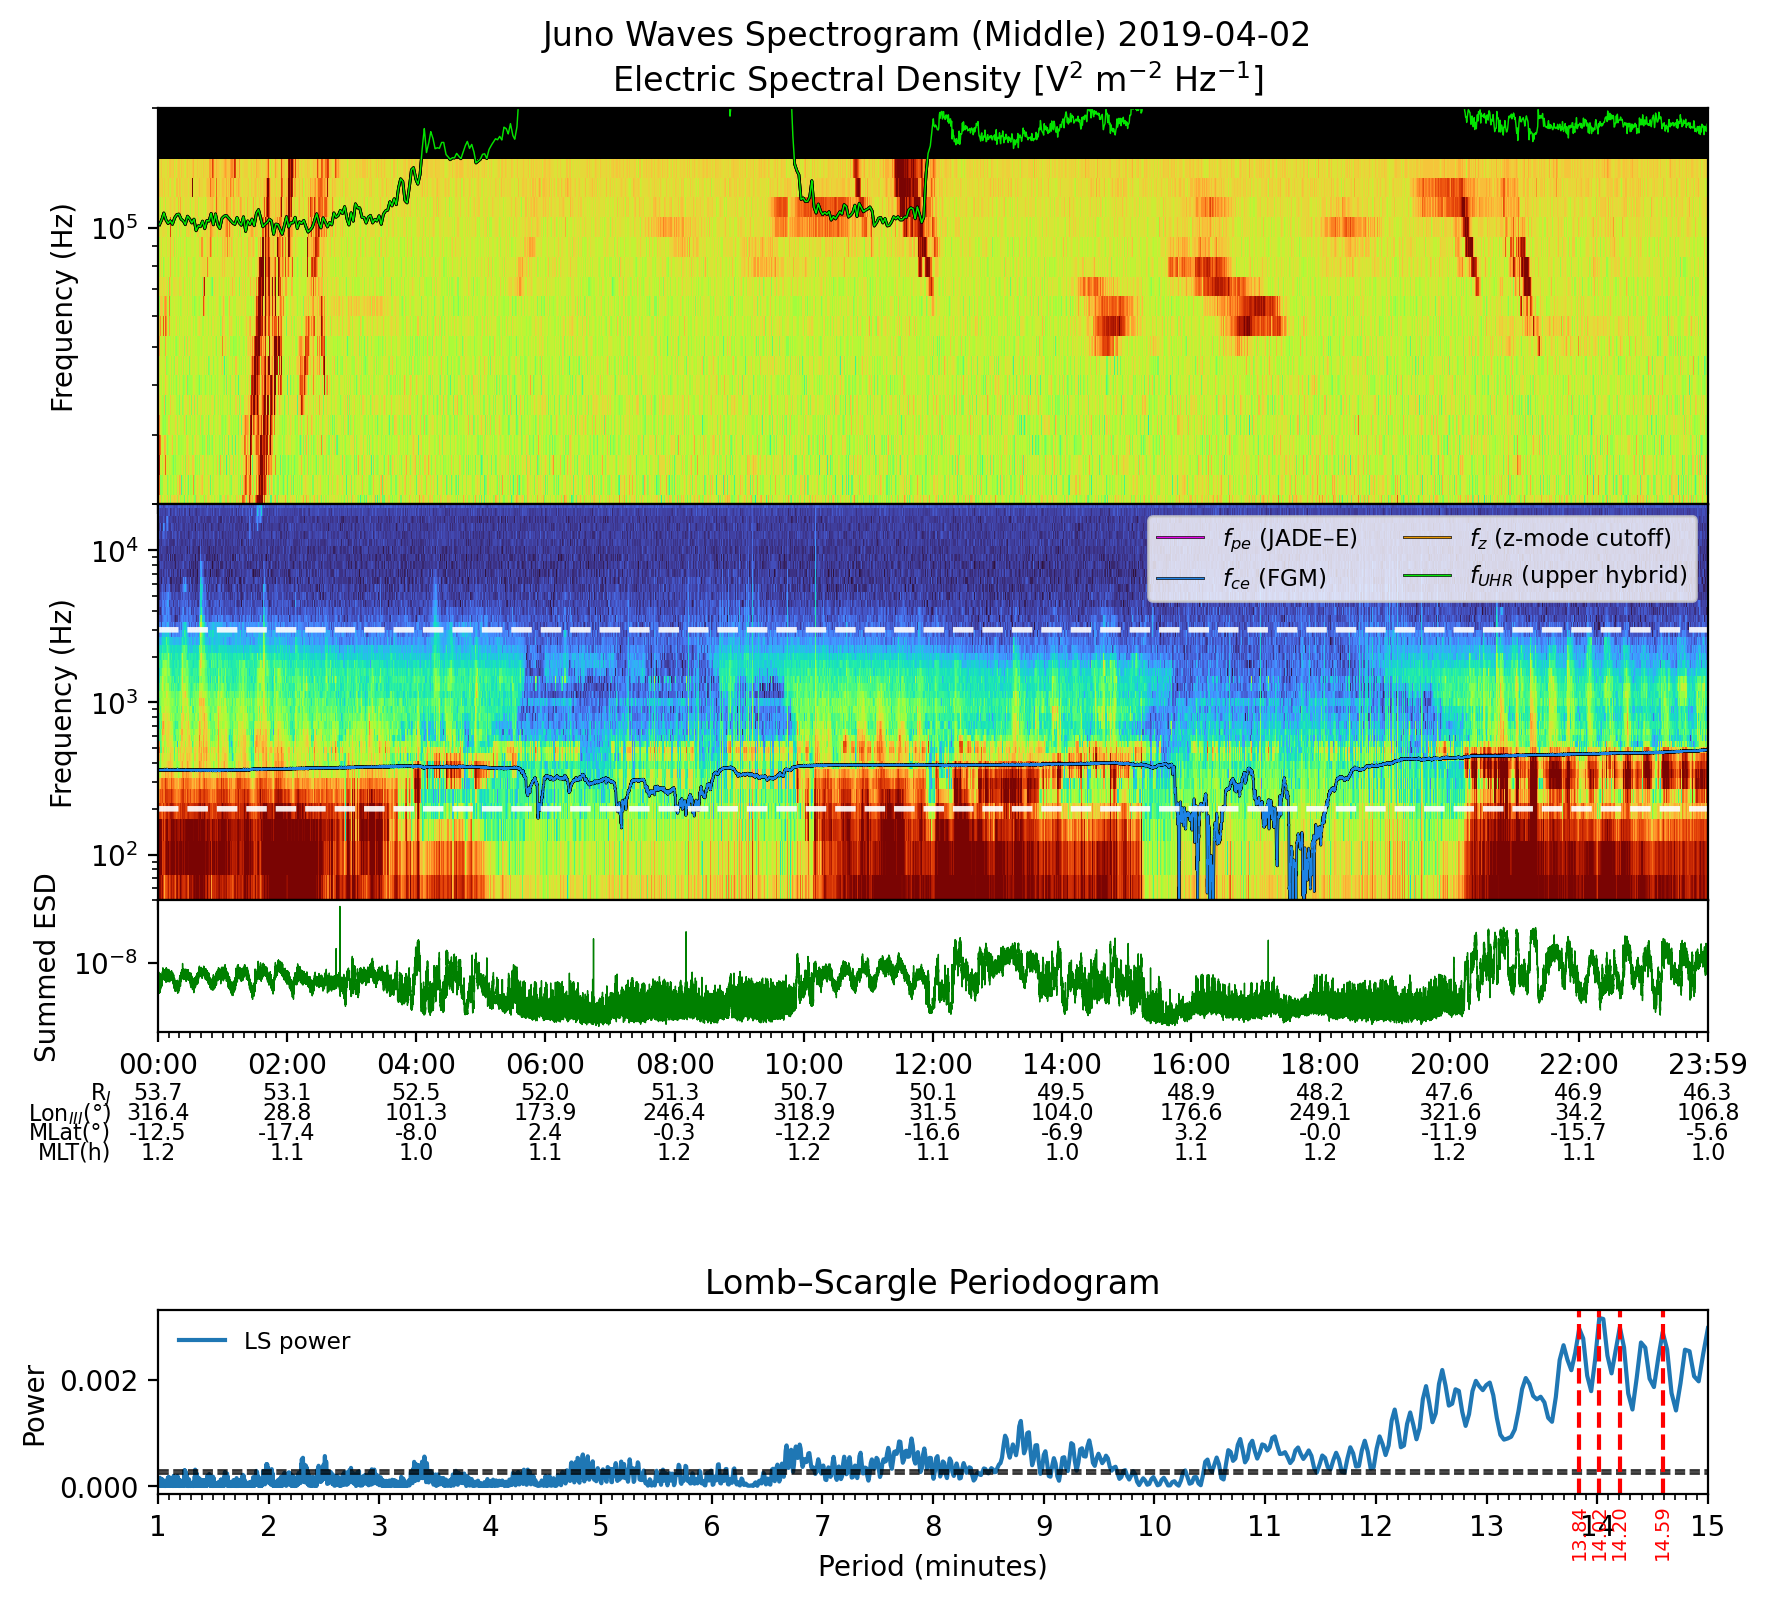

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FixedLocator
from scipy.signal import find_peaks
from das2 import get_source
import matplotlib.patheffects as pe
from matplotlib.gridspec import GridSpec
import das2
from astropy.timeseries import LombScargle

# —————————————————————————————————————————————
# CONFIGURATION
SERVER_URL   = "tag:das2.org,2012:site:/uiowa/juno/wav/survey/das2"
START_TIME   = "2019-04-02T00:00:00"
END_TIME     = "2019-04-03T00:00:00"

# Whistler band for summation (Hz)
WHIS_MIN = 2e2
WHIS_MAX = 3e3

# Periodogram parameters
PERIOD_MIN      = 1       # minutes
PERIOD_MAX      = 15      # minutes
PEAK_DETECT_MIN = 2.5     # only label peaks ≥ this period
NUM_PEAKS       = 4       # top N peaks

# Lomb–Scargle frequency grid resolution
LS_NFREQ = 5000

# Overlay line thickness for f_pe, f_ce, f_z, f_UHR
OVERLAY_LW = 0.5
overlay_alpha = 0.9



# —————————————————————————————————————————————
# 1) Fetch whistler + middle data
source = get_source(SERVER_URL)
whis, middle, _, _ = source.get({'time': (START_TIME, END_TIME)})

# 2) Extract time, frequency, and spectral density
def extract_arrays(d):
    f_arr = d['frequency']['center'].array
    freqs = f_arr[0, :] if f_arr.ndim > 1 else f_arr
    t_arr = d['Time']['center'].array
    times = t_arr[:, 0] if t_arr.ndim > 1 else t_arr
    spec  = d['spec_dens']['center'].array.squeeze()
    if spec.shape[1] != freqs.size:
        spec = spec.T
    return np.array(times, dtype='datetime64[ms]'), freqs, spec

times, freqs, spec = extract_arrays(whis)
times_mid, freqs_mid, spec_mid = extract_arrays(middle)   # NEW

total_hours = (times[-1] - times[0]) / np.timedelta64(1, 'h')
tick_interval_h = 1 if total_hours <= 12 else 2
print("tick_interval_h =", tick_interval_h)

# 3) Sum spectral density across the chosen whistler band
mask_band = (freqs >= WHIS_MIN) & (freqs <= WHIS_MAX)
sum_sd    = spec[:, mask_band].sum(axis=1)

# 4) Build time axis in seconds for detrending
t0    = times[0]
t_sec = (times - t0) / np.timedelta64(1, 's')
dt    = np.median(np.diff(t_sec))

# 5) Detrend: fit and remove linear trend
coeff = np.polyfit(t_sec, sum_sd, 1)
trend = np.polyval(coeff, t_sec)
resid = sum_sd - trend

# 6) Lomb–Scargle periodogram in PERIOD_MIN..PERIOD_MAX
resid0 = resid - np.mean(resid)

fmin = 1.0 / (PERIOD_MAX * 60.0)   # Hz
fmax = 1.0 / (PERIOD_MIN * 60.0)   # Hz
freq = np.linspace(fmin, fmax, LS_NFREQ)

ls = LombScargle(t_sec, resid0, normalization="standard", center_data=False)
power = ls.power(freq)

# Convert to period (minutes) and sort increasing for plotting
periods_ls = (1.0 / freq) / 60.0
order = np.argsort(periods_ls)
periods_ls = periods_ls[order]
power_ls   = power[order]

mask_p    = (periods_ls >= PERIOD_MIN) & (periods_ls <= PERIOD_MAX)
periods_m = periods_ls[mask_p]
pow_m     = power_ls[mask_p]

# Peak detection
peaks, _ = find_peaks(pow_m)
if peaks.size > 0:
    sel = peaks[np.argsort(pow_m[peaks])][-NUM_PEAKS:]
    peak_periods = periods_m[sel]
    peak_periods = peak_periods[peak_periods >= PEAK_DETECT_MIN]
else:
    peak_periods = np.array([])

# FAP thresholds (global over searched frequency range)
try:
    thr_10 = ls.false_alarm_level(0.10, method="baluev",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    thr_01 = ls.false_alarm_level(0.01, method="baluev",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    fap_method = "baluev"
except Exception:
    thr_10 = ls.false_alarm_level(0.10, method="naive",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    thr_01 = ls.false_alarm_level(0.01, method="naive",
                                 minimum_frequency=fmin, maximum_frequency=fmax)
    fap_method = "naive"

# —————————————————————————————————————————————
# 7) Plot: nested GridSpec
fig = plt.figure(figsize=(10, 9), dpi=200)

# Top: middle spec + whistler spec + time series; bottom: LS
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[5, 1], hspace=0.5)

# Three rows in top panel: middle, whistler, TS
inner_gs = outer_gs[0].subgridspec(3, 1, height_ratios=[3, 3, 1], hspace=0.0)

ax_spec_mid = fig.add_subplot(inner_gs[0])                      # NEW
ax_spec     = fig.add_subplot(inner_gs[1], sharex=ax_spec_mid)
ax_ts       = fig.add_subplot(inner_gs[2], sharex=ax_spec_mid)

ax_fft  = fig.add_subplot(outer_gs[1])

# (a1) Middle-band spectrogram
pcm_mid = ax_spec_mid.pcolormesh(
    times_mid, freqs_mid, spec_mid.T,
    norm=LogNorm(vmin=1e-16, vmax=1e-13),
    cmap='turbo',
    shading='nearest'
)
ax_spec_mid.set_ylim(2e4, 20e4)
ax_spec_mid.set_yscale('log')
ax_spec_mid.set_facecolor('black')
ax_spec_mid.set_ylabel('Frequency (Hz)')
ax_spec_mid.set_title(
    f'Juno Waves Spectrogram (Middle) {pd.to_datetime(START_TIME).strftime("%Y-%m-%d")} \n'
    r' Electric Spectral Density [V$^2$ m$^{-2}$ Hz$^{-1}$]'
)

ax_spec_mid.tick_params(labelbottom=False)

# (a2) Whistler-band spectrogram
pcm = ax_spec.pcolormesh(
    times, freqs, spec.T,
    norm=LogNorm(vmin=1e-14, vmax=1e-8),
    cmap='turbo',
    shading='nearest'
)

# ---- Overlay frequencies: f_pe (JADE), f_ce (FGM), f_z, f_UHR ----
t_fpe = None
fpe_hz_series = None

axes_for_overlays = [ax_spec_mid, ax_spec]   # NEW: plot on both

# (A) Use precomputed fpe_hz (Hz) on its own JADE time grid t_fpe_input
try:
    fpe_hz_series = np.asarray(fpe_hz, dtype=float)
except NameError:
    raise RuntimeError(
        "fpe_hz is not defined. Compute it earlier as "
        "fpe_hz = 8980.0 * np.sqrt(ne_cm3) (in Hz)."
    )

try:
    t_fpe_raw = np.asarray(t_fpe_input)
except NameError:
    raise RuntimeError(
        "t_fpe_input is not defined. It should be the JADE time array "
        "corresponding to fpe_hz (either Unix seconds or datetime64)."
    )

if t_fpe_raw.shape[0] != fpe_hz_series.shape[0]:
    raise ValueError(
        f"t_fpe_input length ({t_fpe_raw.shape[0]}) does not match fpe_hz length "
        f"({fpe_hz_series.shape[0]}). They must be the same."
    )

# Convert JADE time → datetime64[ms] for plotting
if np.issubdtype(t_fpe_raw.dtype, np.datetime64):
    t_fpe = t_fpe_raw.astype('datetime64[ms]')
elif np.issubdtype(t_fpe_raw.dtype, np.number):
    # assume Unix seconds
    t_fpe = t_fpe_raw.astype('float64').astype('datetime64[s]').astype('datetime64[ms]')
else:
    raise TypeError(
        "t_fpe_input must be either a datetime64 array or numeric Unix seconds."
    )

# Debug: see f_pe range
print(f"f_pe range (Hz): {np.nanmin(fpe_hz_series):.2e} – {np.nanmax(fpe_hz_series):.2e}")

# Keep only finite/positive values and within the Waves time window
mask_fpe = (
    np.isfinite(fpe_hz_series) &
    (fpe_hz_series > 0) &
    (t_fpe >= times[0]) &
    (t_fpe <= times[-1])
)

if np.any(mask_fpe):
    for ax_ov in axes_for_overlays:   # [ax_spec_mid, ax_spec]
        ax_ov.plot(
            t_fpe[mask_fpe], fpe_hz_series[mask_fpe],
            lw=OVERLAY_LW,
            color='magenta',
            alpha=overlay_alpha,
            path_effects=[pe.Stroke(linewidth=OVERLAY_LW + 0.5,
                                    foreground='black',
                                    alpha=overlay_alpha),
                          pe.Normal()],
            label=r"$f_{pe}$ (JADE–E)" if ax_ov is ax_spec else None
        )
else:
    print("f_pe exists, but no finite/positive points within the Waves time window.")



# (B) f_ce from FGM (blue with white outline + label)
efc_source = das2.get_source('tag:das2.org,2012:site:/uiowa/juno/fgm/electroncyclotron/das2')

ds_efc = efc_source.get({'time': (START_TIME, END_TIME)})[0]
efc_freq = np.asarray(ds_efc['fce']['center'].array, float)
efc_time = np.array(ds_efc['time']['center'].array, dtype='datetime64[ms]')

mask_fce = np.isfinite(efc_freq) & (efc_freq > 0)
for ax_ov in axes_for_overlays:
    ax_ov.plot(
        efc_time[mask_fce], efc_freq[mask_fce],
        color='dodgerblue', linewidth=OVERLAY_LW, alpha=overlay_alpha,
        path_effects=[pe.Stroke(linewidth=OVERLAY_LW + 0.5,
                                foreground='black',
                                alpha=overlay_alpha),
                      pe.Normal()],
        label=r"$f_{ce}$ (FGM)" if ax_ov is ax_spec else None
    )

# (C) f_z and f_UHR (only if f_pe exists)
if (t_fpe is not None) and (fpe_hz_series is not None):
    efc_t_s = (efc_time.astype('datetime64[ms]').astype('int64')).astype(float)
    fpe_t_s = (t_fpe.astype('datetime64[ms]').astype('int64')).astype(float)

    ok_fpe = np.isfinite(fpe_t_s) & np.isfinite(fpe_hz_series) & (fpe_hz_series > 0)
    ok_ce  = np.isfinite(efc_t_s) & np.isfinite(efc_freq) & (efc_freq > 0)

    if np.count_nonzero(ok_fpe) >= 2 and np.count_nonzero(ok_ce) >= 2:
        fpe_t_s2 = fpe_t_s[ok_fpe]
        fpe_hz2  = fpe_hz_series[ok_fpe]

        in_rng = ok_ce & (efc_t_s >= fpe_t_s2.min()) & (efc_t_s <= fpe_t_s2.max())

        if np.any(in_rng):
            fpe_on_ce = np.full_like(efc_t_s, np.nan, dtype=float)
            fpe_on_ce[in_rng] = np.interp(efc_t_s[in_rng], fpe_t_s2, fpe_hz2)

            fce = efc_freq

            # f_z = -f_ce/2 + sqrt((f_ce/2)^2 + f_pe^2)
            fz = -0.5 * fce + np.sqrt((0.5 * fce) ** 2 + fpe_on_ce ** 2)

            # f_UHR = sqrt(f_ce^2 + f_pe^2)
            fuhr = np.sqrt(fce ** 2 + fpe_on_ce ** 2)

            good_fz   = in_rng & np.isfinite(fz)   & (fz > 0)
            good_fuhr = in_rng & np.isfinite(fuhr) & (fuhr > 0)

            print("fz points:", int(np.sum(good_fz)), "| fuhr points:", int(np.sum(good_fuhr)))

            if np.any(good_fz):
                for ax_ov in axes_for_overlays:
                    ax_ov.plot(
                        efc_time[good_fz], fz[good_fz],
                        color='orange', linewidth=OVERLAY_LW, alpha=overlay_alpha,
                        path_effects=[pe.Stroke(linewidth=OVERLAY_LW + 0.5,
                                                foreground='black',
                                                alpha=overlay_alpha),
                                      pe.Normal()],
                        label=r"$f_{z}$ (z-mode cutoff)" if ax_ov is ax_spec else None
                    )
            else:
                print("fz computed but nothing finite/positive to plot (check units/overlap).")

            if np.any(good_fuhr):
                for ax_ov in axes_for_overlays:
                    ax_ov.plot(
                        efc_time[good_fuhr], fuhr[good_fuhr],
                        color='lime', linewidth=OVERLAY_LW, alpha=overlay_alpha,
                        path_effects=[pe.Stroke(linewidth=OVERLAY_LW + 0.5,
                                                foreground='black',
                                                alpha=overlay_alpha),
                                      pe.Normal()],
                        label=r"$f_{UHR}$ (upper hybrid)" if ax_ov is ax_spec else None
                    )
            else:
                print("f_UHR computed but nothing finite/positive to plot (check units/overlap).")
        else:
            print("No overlap between f_pe time range and f_ce time range — cannot compute fz/fUHR.")
    else:
        print("Not enough valid points in f_pe and/or f_ce to compute fz/fUHR.")

# Whistler band guide lines only on whistler panel
ax_spec.set_yscale('log')
ax_spec.set_facecolor('black')
ax_spec.plot(times, [WHIS_MIN] * len(times), '--w', lw=2, alpha=0.9)
ax_spec.plot(times, [WHIS_MAX] * len(times), '--w', lw=2, alpha=0.9)
ax_spec.set_ylabel('Frequency (Hz)')

ax_spec.set_ylim(5e1, 2e4)
ax_spec.tick_params(labelbottom=False)
ax_spec.legend(loc='upper right', frameon=True, ncols=2, fontsize='small')

# (b) Summed time series
ax_ts.plot(times, sum_sd, linewidth=0.5, color='green')
ax_ts.set_ylabel('Summed ESD')
ax_ts.set_xlim(times[0], times[-1])
ax_ts.set_yscale('log')

major = mdates.HourLocator(interval=tick_interval_h)
minor = mdates.MinuteLocator(interval=10)
fmt   = mdates.DateFormatter('%H:%M')
ax_ts.xaxis.set_major_locator(major)
ax_ts.xaxis.set_minor_locator(minor)
ax_ts.xaxis.set_major_formatter(fmt)

# ─── Ephemeris rows below the summed time series ─────────────────────────────
eph_src = get_source('tag:das2.org,2012:site:/uiowa/juno/ephemeris/jovicentric/das2')
ds_eph  = eph_src.get({'time': (START_TIME, END_TIME, int(dt))})[0]

rad   = ds_eph['radius']['center'].array
lon3  = ds_eph['long']['center'].array
mlatE = ds_eph['mlat']['center'].array
mltE  = ds_eph['mlt']['center'].array

if mltE.dtype.kind == 'm':
    mltE = (mltE / np.timedelta64(1, 'h')).astype(float)

# build tick list including endpoints
t0h = times[0].astype('datetime64[h]')
t1h = times[-1].astype('datetime64[h]') + np.timedelta64(1, 'h')
maj = np.arange(t0h, t1h, np.timedelta64(tick_interval_h, 'h'))
all_ticks = np.unique(np.concatenate(([times[0]], maj, [times[-1]])))

py_ticks      = [t.tolist() for t in all_ticks]
all_tick_nums = mdates.date2num(py_ticks)

ax_ts.xaxis.set_major_locator(FixedLocator(all_tick_nums))
ax_ts.xaxis.set_major_formatter(fmt)

idx_eph = [np.argmin(np.abs(times - mt)) for mt in all_ticks]

row_lbls    = ["R$_J$", "Lon$_{III}$(°)", "MLat(°)", "MLT(h)"]
row_arrays  = [rad, lon3, mlatE, mltE]
row_spacing = 0.15

for j, (label, arr) in enumerate(zip(row_lbls, row_arrays)):
    off = -row_spacing * (j + 2)
    sax = ax_ts.secondary_xaxis(off, functions=(lambda x: x, lambda x: x))
    sax.xaxis.set_major_locator(FixedLocator(all_tick_nums))
    vals = arr[idx_eph]
    sax.set_xticklabels([f"{v:.1f}" for v in vals], rotation=0, va='top', fontsize=8)

    sax.spines['bottom'].set_visible(False)
    sax.tick_params(axis='x', length=0)
    sax.xaxis.set_ticks_position('bottom')
    sax.xaxis.set_label_position('bottom')
    txt = sax.set_xlabel(label, fontsize=8, labelpad=-8.5, loc='left')
    txt.set_x(-0.03)
    txt.set_ha('right')

# (c) Lomb–Scargle Periodogram (independent x-axis)
ax_fft.plot(periods_m, pow_m, label='LS power')

ax_fft.axhline(thr_10, ls='--', lw=1, color='k', alpha=0.8)
ax_fft.axhline(thr_01, ls='--', lw=1, color='k', alpha=0.8)

for p in peak_periods:
    ax_fft.axvline(p, ls='--', color='red')
    ax_fft.text(
        p, -0.05, f'{p:.2f}',
        transform=ax_fft.get_xaxis_transform(),
        rotation=90, va='top', ha='center',
        color='red', fontsize=7
    )

ax_fft.set_xlim(PERIOD_MIN, PERIOD_MAX)
ax_fft.set_xlabel('Period (minutes)')
ax_fft.set_ylabel('Power')
ax_fft.set_title('Lomb–Scargle Periodogram')
ax_fft.legend(loc='upper left', frameon=False, ncols=2, fontsize='small')
ax_fft.xaxis.set_major_locator(MultipleLocator(1))
ax_fft.xaxis.set_minor_locator(AutoMinorLocator(10))

plt.show()
